# Vehicle permit payments by segment

In Chile, every vehicle pays a yearly circulation permit to its municipality. This notebook splits the 2023 permit payments of Calbuco, a municipality in southern Chile, into eight segments and compares the amounts paid in each one.

The segments combine three variables, each split in two:

- **vehicle group:** heavy (cargo and public transport) or light,
- **payment channel:** in person or online,
- **vehicle age:** built in 2000 or earlier, or in 2001 or later.

**Data.** The municipality's open data on circulation permits for 2023, with the plate number and the other vehicle identifiers removed. Amounts are in Chilean pesos (CLP). See [`data/README.md`](../data/README.md).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.options.display.float_format = "{:,.0f}".format

df = pd.read_csv("../data/vehicle-permits-calbuco-2023.csv")
df.head()

,vehicle_group,vehicle_year,payment_channel,amount_paid
0,Vehiculo Liviano,2020,Presencial,120094
1,Vehiculo Liviano,2001,Presencial,42337
2,Carga,2009,Presencial,213883
3,Vehiculo Liviano,2013,Presencial,27357
4,Vehiculo Liviano,1994,Presencial,42337


In [2]:
print(df["vehicle_group"].value_counts(), "\n")
print(df["payment_channel"].value_counts(), "\n")
print(df["vehicle_year"].agg(["min", "max"]))

vehicle_group
Vehiculo Liviano      7419
Transporte Publico     440
Carga                   89
Name: count, dtype: int64 

payment_channel
Presencial    5649
Internet      2299
Name: count, dtype: int64 

min    1980
max    2023
Name: vehicle_year, dtype: int64


## Build the eight segments

In the spreadsheet, the segment of each row was a combination of three labels, built with `=CONCATENATE(A3," - ",B3," - ",C3)`. In pandas each variable becomes a boolean mask, and the masks combine with `&` and `~` (not).

In [3]:
heavy = df["vehicle_group"].isin(["Carga", "Transporte Publico"])
online = df["payment_channel"] == "Internet"
old = df["vehicle_year"] <= 2000

segments = {
    "G1": heavy & ~online & old,
    "G2": heavy & ~online & ~old,
    "G3": heavy & online & old,
    "G4": heavy & online & ~old,
    "G5": ~heavy & ~online & old,
    "G6": ~heavy & ~online & ~old,
    "G7": ~heavy & online & old,
    "G8": ~heavy & online & ~old,
}
groups = {name: df.loc[mask, "amount_paid"] for name, mask in segments.items()}

pd.DataFrame({
    "vehicles": ["heavy"] * 4 + ["light"] * 4,
    "payment": ["in person", "in person", "online", "online"] * 2,
    "built": ["2000 or earlier", "2001 or later"] * 4,
    "payments": [len(g) for g in groups.values()],
}, index=list(groups))

,vehicles,payment,built,payments
G1,heavy,in person,2000 or earlier,29
G2,heavy,in person,2001 or later,495
G3,heavy,online,2000 or earlier,2
G4,heavy,online,2001 or later,3
G5,light,in person,2000 or earlier,395
G6,light,in person,2001 or later,4730
G7,light,online,2000 or earlier,137
G8,light,online,2001 or later,2157


## Descriptive statistics

The same eight formulas as in the other notebooks (`=COUNT`, `=AVERAGE`, `=MAX`, `=MIN`, `=MODE`, `=MEDIAN`, `=STDEV`), one column per segment.

In [4]:
def summary(s):
    """The statistics the course asked for, in the same order as the spreadsheet."""
    return pd.Series({
        "count": s.count(),
        "mean": s.mean(),
        "median": s.median(),
        "mode": s.mode().iloc[0] if s.duplicated().any() else float("nan"),
        "std": s.std(),
        "max": s.max(),
        "min": s.min(),
        "range": s.max() - s.min(),
    })

stats = pd.DataFrame({name: summary(g) for name, g in groups.items()})
stats

,G1,G2,G3,G4,G5,G6,G7,G8
count,29,495,2,3,395,"4,730",137,"2,157"
mean,"189,251","68,657","163,595","83,848","34,245","104,613","30,094","67,955"
median,"172,218","63,074","163,595","74,702","30,885","58,994","30,884","42,113"
mode,"234,901","63,074",NaN,NaN,"30,885","30,885","30,884","30,884"
std,"94,055","35,747","125,714","20,941","11,585","131,639","4,324","64,502"
max,"396,640","340,831","252,488","107,806","92,586","1,965,921","35,505","690,446"
min,"63,074","2,586","74,702","69,035","15,443",0,"15,442","15,442"
range,"333,566","338,245","177,786","38,771","77,143","1,965,921","20,063","675,004"


- Among light vehicles, newer ones pay more: a median of 58,994 pesos in person (G6) against 30,885 for the older ones (G5). The permit is a percentage of the vehicle's appraised value, which falls as the vehicle ages.
- The most repeated amount among light vehicles is 30,884 or 30,885 pesos. That is half of the January 2023 *Unidad Tributaria Mensual* (UTM, 61,769 pesos), the minimum permit the law sets for these vehicles, so older and cheaper cars cluster at the floor.
- G3 and G4 have only 2 and 3 payments. Statistics over so few values say little, and with no repeated value there is no mode (Excel shows `#N/A`).

## Frequency table

Classes of 500,000 pesos. In the spreadsheet the first one was `=COUNTIF(J:J,"<="&D22)` and the rest `=COUNTIFS(J:J,">"&C23,J:J,"<="&D23)`, so each class includes its upper limit.

In [5]:
bins = [0, 500_000, 1_000_000, 1_500_000, 2_000_000]
labels = ["0 to 500k", "500k to 1M", "1M to 1.5M", "1.5M to 2M"]
freq = pd.DataFrame({
    name: pd.cut(g, bins=bins, labels=labels, include_lowest=True).value_counts(sort=False)
    for name, g in groups.items()
})
freq

,G1,G2,G3,G4,G5,G6,G7,G8
amount_paid,,,,,,,,
0 to 500k,29,495,2,3,395,4642,137,2153
500k to 1M,0,0,0,0,0,75,0,4
1M to 1.5M,0,0,0,0,0,8,0,0
1.5M to 2M,0,0,0,0,0,5,0,0


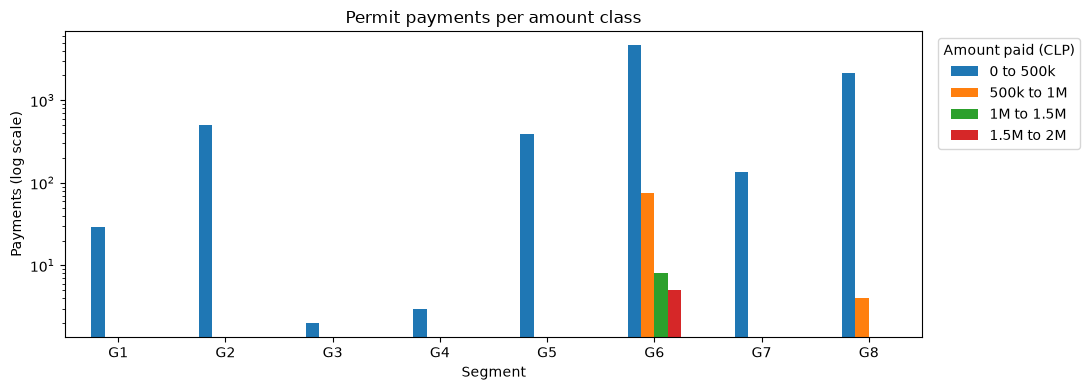

In [6]:
ax = freq.T.plot(kind="bar", figsize=(11, 4), rot=0, logy=True)
ax.set_xlabel("Segment")
ax.set_ylabel("Payments (log scale)")
ax.set_title("Permit payments per amount class")
ax.legend(title="Amount paid (CLP)", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

Almost every payment is below 500,000 pesos. Only light vehicles paid in person (G6) reach the higher classes, with 88 payments above 500,000. The vertical axis is logarithmic so that those small counts stay visible next to the thousands in the first class.

## Notes

- Each row is a payment, not a vehicle: a permit paid in two installments appears twice, and each installment is half the amount. That is part of why the minimum in G7 and G8 is 15,442 pesos, a quarter of the UTM.
- 13 payments are 0 pesos, probably exemptions. They are included, as in the spreadsheet, and they set the minimum of G6.
- The spreadsheet labeled the age classes "1980 to 2000" and "2000 to 2023", which overlap. Its formulas put the 62 vehicles built in 2000 in the older class, and the masks above do the same.